# Autoetiquetado de Nutrition5k — pipeline final (v2) y etiquetado masivo

Genera máscaras semánticas de ingredientes para Nutrition5k usando la metadata de cada plato como guía, y las deja listas para el fine-tuning.

**Pipeline por plato**
1. **SegFormer-B1** → primer plano (qué es comida).
2. **SAM2** → regiones candidatas.
3. **CLIP** → qué ingrediente es cada región, **solo entre los ingredientes de la metadata** (+ opciones de rechazo, incluyendo los ingredientes reales que no segmentamos).
4. Todo se guarda en crudo (`.npz`); **las decisiones se toman después** con `decide()`.

**Mejoras v2 ya validadas** (con tu set limpio de 40 platos: mIoU 0.564 → ~0.75): recortes cuadrados, máscara + caja, rechazos extra, atajo de platos de una clase y **presencia obligatoria**.

**Decisión de esta versión: la regla de vecinos (`neighbor`) se eliminó.** En tu medición acertó solo 0.62 (frente a 0.98 de las regiones aceptadas directamente) y con muy poca evidencia (29 % de esas regiones tenía referencia). Para etiquetas de entrenamiento es mejor dejar esas regiones sin etiquetar (`255`, ignoradas) que meter ruido.

| Parte | Contenido |
|---|---|
| 1–3 | Configuración, metadata/vocabulario, modelos |
| 4 | Pipeline por plato (v2) |
| 5 | Decisión (`decide`, `DEC_FINAL`) |
| 6 | **Verificación de lo ya hecho** (reutiliza `raw_labels/` y `raw_labels_v2_*/`) |
| 7 | Set limpio y evaluación (opcional, para validar cambios) |
| 8 | **Etiquetado masivo** |
| 9 | **Visualización** de platos etiquetados |
| 10 | **Exportar** dataset (etiquetas + split + estadísticas) |

**Nada empieza de cero:** los platos que ya tienen `.npz` v2 se saltan; los que solo tienen v1 reutilizan sus regiones (sin repetir SAM ni B1); solo los platos nuevos corren el pipeline completo.

Las celdas con corridas largas están protegidas por banderas en `False`.

## 1. Configuración

In [1]:
import csv, json, math, random, time, traceback
from collections import Counter
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from scipy import ndimage

import torch
import torch.nn.functional as F

# ---------------- RUTAS ----------------
ROOT      = Path(r"C:\nutrition5k")
SEG_PATH  = r"C:\foodseg_segformer\mit-b1"
V1_DIR    = Path("raw_labels")       # salidas del pipeline anterior (solo se LEEN: regiones reutilizables)
CLEAN_DIR = Path("clean_set")        # set limpio con tus anotaciones (se conserva)

# ---------------- PARÁMETROS DEL PIPELINE (no cambiar si quieres reutilizar lo hecho) ----------------
device        = "cuda"
INPUT_SIZE    = (512, 512)           # tamaño con el que se entrenó B1
MIN_AREA_CAND = 400                  # píxeles; regiones candidatas más pequeñas se descartan
FG_OVERLAP    = 0.8                  # fracción mínima de una máscara de SAM sobre comida
SAM_PARAMS    = dict(points_stride=48, conf_thres=0.75, stability_score_thresh=0.85)
CLIP_NAME     = "openai/clip-vit-large-patch14"
CLIP_FP16     = False
CLIP_CHUNK    = 16                   # recortes por lote en CLIP (baja si te quedas sin VRAM)
IGNORE        = 255                  # comida sin clase segura

# Banderas de la versión v2: cada combinación escribe en su propia carpeta
RAW_CFG = dict(square_pad=True, bbox_avg=True, reject_excluded=True, single_shortcut=True)

def raw_tag(cfg):
    return "_".join(f"{k[:2]}{int(v)}" for k, v in cfg.items())       # p. ej. sq1_bb1_re1_si1

def v2_dir(cfg=None):
    return Path(f"raw_labels_v2_{raw_tag(cfg or RAW_CFG)}")

OUT_V2 = v2_dir()
print("carpeta v2 activa:", OUT_V2)

carpeta v2 activa: raw_labels_v2_sq1_bb1_re1_si1


## 2. Metadata y vocabulario

`EXCLUDE`, `MERGE` y `MIN_G` definen las clases. **Si los cambias, los ids de clase cambian** y los `.npz` ya guardados dejan de coincidir con el vocabulario (la verificación de la Parte 6 te avisa).

In [2]:
def read_dishes(csv_path):
    dishes = {}
    with open(csv_path, newline="") as f:
        for row in csv.reader(f):
            dish_id = row[0]
            totals = dict(zip(["kcal", "mass_g", "fat_g", "carb_g", "protein_g"], map(float, row[1:6])))
            ingredients = []
            for i in range(6, len(row), 7):          # bloques de 7 columnas por ingrediente
                block = row[i:i + 7]
                if len(block) < 7:
                    break
                ingredients.append({"id": block[0], "name": block[1], "grams": float(block[2])})
            dishes[dish_id] = {"totals": totals, "ingredients": ingredients}
    return dishes

dishes = {}
for name in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
    dishes.update(read_dishes(ROOT / "metadata" / name))

image_dirs = {p.name for p in (ROOT / "realsense_overhead").iterdir() if p.is_dir()}
usable = sorted(set(dishes) & image_dirs)
print("platos en metadata:", len(dishes), "| con imagen:", len(image_dirs), "| con ambos:", len(usable))

platos en metadata: 5006 | con imagen: 3490 | con ambos: 3490


In [3]:
EXCLUDE = {
    "olive oil", "salt", "pepper", "vinegar", "lemon juice", "mustard",
    "garlic", "thyme", "parsley", "cilantro", "shallots", "jalapenos",
    "lime", "sugar", "soy sauce",
}
MERGE = {
    "white rice": "rice", "brown rice": "rice",
    "arugula": "leafy greens", "spinach (raw)": "leafy greens", "kale": "leafy greens",
    "chard": "leafy greens", "mixed greens": "leafy greens", "bok choy": "leafy greens",
    "lettuce": "leafy greens",
    "chicken thighs": "chicken",
    "pepperoni pizza": "cheese pizza",
}
MIN_G = 10

def segmentable(dish_id):
    """{clase: gramos} solo con lo que vale la pena segmentar."""
    out = {}
    for ing in dishes[dish_id]["ingredients"]:
        name = ing["name"]
        if name in EXCLUDE or ing["grams"] < MIN_G:
            continue
        label = MERGE.get(name, name)
        out[label] = out.get(label, 0) + ing["grams"]
    return out

def dish_extra_reject(dish_id, max_n=6):
    """Ingredientes REALES del plato que NO segmentamos (excluidos o <MIN_G): opciones de rechazo para CLIP."""
    keep = set(segmentable(dish_id))
    cand = {}
    for ing in dishes[dish_id]["ingredients"]:
        lab = MERGE.get(ing["name"], ing["name"])
        if lab in keep:
            continue
        cand[lab] = cand.get(lab, 0) + ing["grams"]
    return [n for n, _ in sorted(cand.items(), key=lambda kv: -kv[1])[:max_n]]

label_freq = Counter()
for d in usable:
    for label in segmentable(d):
        label_freq[label] += 1

CLASS_NAMES = sorted(label_freq)                             # clases ordenadas alfabéticamente
CLASS_ID    = {n: i + 1 for i, n in enumerate(CLASS_NAMES)}  # 0 = fondo, 255 = ignorar
print("clases:", len(CLASS_NAMES))

clases: 189


## 3. Modelos y utilidades de CLIP

CLIP se usa con embeddings separados de imagen y de texto (`logit = escala × coseno`), equivalente a `logits_per_image` pero permitiendo lotes pequeños, caché de textos y **guardar los embeddings de cada región** para re-puntuar sin recalcular imágenes.

In [4]:
from transformers import SegformerForSemanticSegmentation, CLIPModel, CLIPProcessor
from ultralytics import SAM

seg = SegformerForSemanticSegmentation.from_pretrained(SEG_PATH).to(device).eval()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
if CLIP_FP16:
    clip_model.half()
clip_dtype  = next(clip_model.parameters()).dtype
LOGIT_SCALE = clip_model.logit_scale.exp().item()
CLIP_DIM    = clip_model.config.projection_dim

sam = SAM("sam2.1_b.pt")
def init_sam():
    sam(str(ROOT / "realsense_overhead" / usable[0] / "rgb.png"), verbose=False)   # crea el predictor interno
    gen = sam.predictor.__class__.generate
    sam.predictor.generate = partial(gen, sam.predictor, **SAM_PARAMS)
init_sam()
print("B1 num_labels:", seg.config.num_labels, "| CLIP dim:", CLIP_DIM, "| logit_scale:", round(LOGIT_SCALE, 1))

c:\Users\mjcor\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 15:05:09.290000 8304 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 590/590 [00:01<00:00, 361.76it/s]


B1 num_labels: 104 | CLIP dim: 768 | logit_scale: 100.0


In [5]:
PROMPT_NAME = {                      # nombres más naturales para CLIP (amplía según lo que veas)
    "rice": "cooked rice",
    "leafy greens": "leafy salad greens",
    "wheat berry": "cooked wheat berries",
}
REJECT = ["an empty white plate", "a sauce stain", "a metal tray"]

def load_rgb(dish_id):
    return np.array(Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB"))

def make_crop(img, mask, masked=True, pad=10, square=False):
    """Recorte de la región. masked=True pinta gris fuera de la máscara; masked=False es la caja completa.
    square=True rellena a cuadrado ANTES de CLIP (CLIPProcessor hace center crop y cortaría los extremos)."""
    ys, xs = np.where(mask)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, img.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, img.shape[1])
    crop = img[y0:y1, x0:x1].copy()
    if masked:
        crop[~mask[y0:y1, x0:x1]] = 127
    if square:
        h, w = crop.shape[:2]
        s = max(h, w)
        canvas = np.full((s, s, 3), 127, np.uint8)
        oy, ox = (s - h) // 2, (s - w) // 2
        canvas[oy:oy + h, ox:ox + w] = crop
        crop = canvas
    return Image.fromarray(crop)

_DUMMY_TXT = clip_proc(text=["a"], return_tensors="pt", padding=True).to(device)
_DUMMY_IMG = torch.zeros(1, 3, 224, 224, device=device, dtype=clip_dtype)
_TXT = {}

@torch.no_grad()
def embed_crops(crops):
    feats = []
    for i in range(0, len(crops), CLIP_CHUNK):
        pv = clip_proc(images=crops[i:i + CLIP_CHUNK], return_tensors="pt")["pixel_values"]
        out = clip_model(**_DUMMY_TXT, pixel_values=pv.to(device, clip_dtype))
        feats.append(F.normalize(out.image_embeds.float(), dim=-1))
    return torch.cat(feats) if feats else torch.zeros(0, CLIP_DIM, device=device)

@torch.no_grad()
def text_feat(prompt):
    if prompt not in _TXT:
        t = clip_proc(text=[prompt], return_tensors="pt", padding=True).to(device)
        out = clip_model(**t, pixel_values=_DUMMY_IMG)
        _TXT[prompt] = F.normalize(out.text_embeds.float(), dim=-1)[0]
    return _TXT[prompt]

def label_prompts(labels):
    return [f"a photo of {PROMPT_NAME.get(l, l)}, a type of food" for l in labels]

def probs_from_feats(img_feats, prompts):
    T = torch.stack([text_feat(p) for p in prompts])
    return (LOGIT_SCALE * img_feats @ T.T).softmax(-1).cpu().numpy()

# 4. Pipeline por plato (v2)

| Bandera | Qué hace |
|---|---|
| `square_pad` | Recorte cuadrado antes de CLIP (no pierde extremos) |
| `bbox_avg` | Promedia embedding enmascarado + caja completa (contexto) |
| `reject_excluded` | Ingredientes reales no segmentados (aceite, salsas, <10 g) como rechazos |
| `single_shortcut` | Plato de **una sola clase**: todo el primer plano es esa clase (sin SAM ni CLIP) |

Si el plato ya está en `raw_labels/`, se **reutilizan** su `region_map` y `fg`. Cada `.npz` v2 guarda `region_map`, `fg`, `probs`, `labels`, `reject_names` y `emb` (embeddings por región).

In [6]:
@torch.no_grad()
def foreground_mask(dish_id, bg_index=0):
    img = Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB")
    H, W = img.size[1], img.size[0]
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float().div(255)[None].to(device)
    x = F.interpolate(x, size=INPUT_SIZE, mode="bilinear", align_corners=False)
    x = (x - MEAN) / STD
    logits = seg(pixel_values=x).logits
    logits = F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    pred = logits.argmax(dim=1)[0].cpu().numpy()
    return pred, pred != bg_index

def auto_masks(dish_id):
    r = sam(str(ROOT / "realsense_overhead" / dish_id / "rgb.png"), verbose=False)[0]
    return r.masks.data.cpu().numpy().astype(bool)

def candidate_regions(dish_id):
    sam_masks = auto_masks(dish_id)
    pred, fg = foreground_mask(dish_id)
    regions, covered = [], np.zeros_like(fg)
    for m in sorted(sam_masks, key=lambda m: m.sum()):                     # de pequeña a grande
        area = m.sum()
        if area < MIN_AREA_CAND or (m & fg).sum() / area < FG_OVERLAP:
            continue
        m = m & fg & ~covered
        if m.sum() < MIN_AREA_CAND:
            continue
        regions.append({"mask": m, "source": "sam"})
        covered |= m
    residual = fg & ~covered                                               # comida no cubierta por SAM
    for c in np.unique(pred[residual]):
        comp, n = ndimage.label(residual & (pred == c))
        for k in range(1, n + 1):
            m = comp == k
            if m.sum() >= MIN_AREA_CAND:
                regions.append({"mask": m, "source": "residual", "b1_class": int(c)})
    return regions, fg

def atomic_savez(path, **arrays):
    """Escribe a un temporal y renombra: nunca deja un .npz a medias."""
    path = Path(path)
    tmp = path.with_suffix(".part")
    with open(tmp, "wb") as f:
        np.savez_compressed(f, **arrays)
    tmp.replace(path)

def get_fg(dish_id):
    p = V1_DIR / f"{dish_id}.npz"
    if p.exists():
        with np.load(p) as z:
            return z["fg"]
    return foreground_mask(dish_id)[1]

def get_regions(dish_id):
    """(máscaras, region_map, fg). Reutiliza lo ya guardado en V1_DIR si existe."""
    p = V1_DIR / f"{dish_id}.npz"
    if p.exists():
        with np.load(p) as z:
            rm, fg, R = z["region_map"].astype(np.uint16), z["fg"], len(z["probs"])
        return [rm == i for i in range(1, R + 1)], rm, fg
    regs, fg = candidate_regions(dish_id)
    rm = np.zeros(fg.shape, np.uint16)
    for i, r in enumerate(regs, start=1):
        rm[r["mask"]] = i
    return [r["mask"] for r in regs], rm, fg

def region_embeddings(img, masks, cfg):
    fm = embed_crops([make_crop(img, m, masked=True, square=cfg["square_pad"]) for m in masks])
    if not cfg["bbox_avg"]:
        return fm
    fb = embed_crops([make_crop(img, m, masked=False, square=cfg["square_pad"]) for m in masks])
    return F.normalize(fm + fb, dim=-1)

def v2_prompts(labels, extra):
    return label_prompts(labels) + [f"a photo of {r}" for r in REJECT] \
         + [f"a photo of {PROMPT_NAME.get(n, n)}" for n in extra]

def save_raw_v2(dish_id, cfg=None, out_dir=None):
    cfg = cfg or RAW_CFG
    out_dir = Path(out_dir or v2_dir(cfg)); out_dir.mkdir(exist_ok=True)
    labels = list(segmentable(dish_id).keys())
    empty_emb = np.zeros((0, CLIP_DIM), np.float16)

    if cfg["single_shortcut"] and len(labels) == 1:                        # atajo: plato de una sola clase
        fg = get_fg(dish_id)
        comp, n = ndimage.label(fg)
        rm, keep = np.zeros(fg.shape, np.uint16), 0
        for k in range(1, n + 1):
            m = comp == k
            if m.sum() >= MIN_AREA_CAND:
                keep += 1
                rm[m] = keep
        atomic_savez(out_dir / f"{dish_id}.npz", region_map=rm, fg=fg,
                     probs=np.ones((keep, 1), np.float32), labels=np.array(labels),
                     reject_names=np.array([], dtype=str), emb=empty_emb)
        return

    masks, rm, fg = get_regions(dish_id)
    extra = dish_extra_reject(dish_id) if cfg["reject_excluded"] else []
    if masks:
        feats = region_embeddings(load_rgb(dish_id), masks, cfg)
        probs = probs_from_feats(feats, v2_prompts(labels, extra))
        emb = feats.cpu().numpy().astype(np.float16)
    else:
        probs, emb = np.zeros((0, 1)), empty_emb
    atomic_savez(out_dir / f"{dish_id}.npz", region_map=rm, fg=fg, probs=probs, labels=np.array(labels),
                 reject_names=np.array(REJECT + extra, dtype=str), emb=emb)

def check_reproduce(dish_id):
    """Con TODAS las banderas apagadas, v2 debe reproducir las probabilidades del v1 guardado."""
    cfg0 = dict(square_pad=False, bbox_avg=False, reject_excluded=False, single_shortcut=False)
    tmp = Path("tmp_check")
    save_raw_v2(dish_id, cfg0, tmp)
    a = np.load(V1_DIR / f"{dish_id}.npz")["probs"]
    b = np.load(tmp / f"{dish_id}.npz")["probs"]
    print(dish_id, "formas v1/v2:", a.shape, b.shape,
          "| max|dif| =", float(np.abs(a - b).max()) if a.size and a.shape == b.shape else "n/a")

def purge_corrupt(out_dir):
    """Borra .npz ilegibles (por si una corrida se cortó escribiendo)."""
    bad = []
    for f in Path(out_dir).glob("*.npz"):
        try:
            with np.load(f) as z:
                _ = z["region_map"], z["probs"]
        except Exception:
            bad.append(f)
    for f in bad:
        f.unlink()
    print(len(list(Path(out_dir).glob("*.npz"))), "válidos;", len(bad), "borrados en", out_dir)

def run_batch(todo, fn, tag, max_consecutive_errors=5, log_every=25):
    """Corre fn(plato) sobre todo; se detiene tras errores seguidos y guarda los tracebacks."""
    t0, errors, consec = time.time(), [], 0
    for n, d in enumerate(todo, start=1):
        try:
            fn(d)
            consec = 0
        except Exception:
            tb = traceback.format_exc()
            errors.append((d, tb)); consec += 1
            if len(errors) == 1:
                print(f"PRIMER ERROR (plato {d}):\n{tb}")
            if consec >= max_consecutive_errors:
                print(f"\n{consec} errores seguidos: me detengo en el plato {n}/{len(todo)}.\n"
                      "Revisa el traceback. Si es un error de CUDA (OOM, device-side assert...), reinicia el kernel "
                      "antes de reanudar: la corrida salta lo ya guardado.")
                break
        if n % log_every == 0:
            torch.cuda.empty_cache()
            rate = (time.time() - t0) / n
            print(f"{n}/{len(todo)} | {rate:.1f} s/plato | faltan ~{rate * (len(todo) - n) / 60:.0f} min | errores: {len(errors)}")
    if errors:
        Path(f"errors_{tag}.log").write_text("\n\n".join(f"{d}\n{tb}" for d, tb in errors), encoding="utf-8")
    print(f"terminado ({tag}); platos con error: {len(errors)}")
    return errors

# 5. Decisión: de probabilidades a etiquetas

`decide()` aplica sobre los `.npz`, sin recalcular nada:
- **base**: se acepta la región si gana un ingrediente (no un rechazo), con prob ≥ `thr` y área ≥ `min_area`.
- **presence**: si la metadata dice que hay ≥ `presence_min_g` gramos de un ingrediente y **ninguna** región se aceptó como ese ingrediente, se le asigna la región grande aún no aceptada que más se le parezca si su prob ≥ `presence_floor`.

`presence_floor` es el parámetro clave. En tu set limpio, las regiones rescatadas acertaron **0.56** con prob ≤ 0.3, **0.71** entre 0.3 y 0.5 y **0.93** entre 0.5 y 0.7 (pocas regiones por franja). `0.4` es un punto intermedio; la Parte 7 trae un barrido para ajustarlo con datos.

In [7]:
DEC_BASE  = dict(thr=0.7, min_area=1500, presence=False)
DEC_FINAL = dict(thr=0.7, min_area=1500, presence=True,
                 presence_min_g=20, presence_floor=0.4, presence_min_area=1500)

def dec_variant(**kw):
    d = dict(DEC_FINAL); d.update(kw); return d

def load_raw(dish_id, npz_dir):
    with np.load(Path(npz_dir) / f"{dish_id}.npz") as z:
        return dict(region_map=z["region_map"], fg=z["fg"], probs=z["probs"],
                    labels=[str(l) for l in z["labels"]])

def dishes_in(npz_dir):
    return sorted(f.stem for f in Path(npz_dir).glob("*.npz"))

def decide(raw, dish_id, dec):
    """Lista de regiones con label, prob, area, accepted y reason ('base' o 'presence')."""
    probs, labels, rm = raw["probs"], raw["labels"], raw["region_map"]
    R = len(probs)
    areas = np.bincount(rm.ravel().astype(np.int64), minlength=R + 1)[1:R + 1]
    regs = []
    for i in range(R):
        p = probs[i]
        k = int(p.argmax())
        name = labels[k] if k < len(labels) else None          # None = ganó una opción de rechazo
        ok = name is not None and p[k] >= dec["thr"] and areas[i] >= dec["min_area"]
        regs.append(dict(rid=i + 1, label=name, prob=float(p[k]), area=int(areas[i]),
                         accepted=bool(ok), reason="base" if ok else ""))
    if dec.get("presence"):
        grams = segmentable(dish_id)
        for name in sorted(labels, key=lambda n: -grams.get(n, 0)):     # primero los ingredientes más pesados
            if grams.get(name, 0) < dec["presence_min_g"]:
                continue
            if any(r["accepted"] and r["label"] == name for r in regs):
                continue
            j = labels.index(name)
            cands = [(float(probs[i][j]), i) for i, r in enumerate(regs)
                     if not r["accepted"] and r["area"] >= dec["presence_min_area"]]
            if not cands:
                continue
            pj, i = max(cands)
            if pj >= dec["presence_floor"]:
                regs[i].update(label=name, prob=pj, accepted=True, reason="presence")
    return regs

def build_sem(raw, regs):
    """Mapa semántico: 0 = fondo, 1..K = clase, 255 = comida sin clase segura."""
    sem = np.zeros(raw["fg"].shape, np.uint8)
    sem[raw["fg"]] = IGNORE
    for r in regs:
        if r["accepted"]:
            sem[raw["region_map"] == r["rid"]] = CLASS_ID[r["label"]]
    return sem

def coverage_table(npz_dir, dishes_list, dec):
    rows = []
    for d in dishes_list:
        raw = load_raw(d, npz_dir)
        regs = decide(raw, d, dec)
        food = int(raw["fg"].sum())
        lab = sum(r["area"] for r in regs if r["accepted"])
        rows.append(dict(dish=d, food_px=food, labeled_px=lab, labeled_frac=lab / food if food else 0.0,
                         n_regions=len(regs), n_accepted=sum(r["accepted"] for r in regs),
                         n_presence=sum(r["reason"] == "presence" for r in regs)))
    return pd.DataFrame(rows)

def class_table(npz_dir, dishes_list, dec, top=25):
    rows = []
    for d in dishes_list:
        raw = load_raw(d, npz_dir)
        for r in decide(raw, d, dec):
            if r["accepted"]:
                rows.append(dict(dish=d, label=r["label"], area=r["area"], prob=r["prob"]))
    df = pd.DataFrame(rows)
    t = (df.groupby("label").agg(platos=("dish", "nunique"), regiones=("dish", "size"),
                                 pixeles=("area", "sum"), prob_media=("prob", "mean"))
           .sort_values("pixeles", ascending=False))
    print(len(t), "clases con al menos una región aceptada;", int((t.platos >= 30).sum()), "con ≥30 platos")
    return t.head(top)

# 6. Verificación de lo ya hecho

Antes de etiquetar más, comprueba el estado:
- cuántos platos hay en `raw_labels/` (v1) y en la carpeta v2 activa;
- borra `.npz` corruptos (si una corrida anterior se cortó);
- verifica que el **vocabulario no cambió**: las `labels` guardadas deben coincidir con las que da hoy `segmentable()`. Si no coinciden, cambiaste `EXCLUDE`/`MERGE` y esos `.npz` hay que regenerarlos.
- con `CHECK = True` además comprueba que v2 con banderas apagadas reproduce las probabilidades del v1 (diferencia ≈ 0).

In [8]:
def verify_state(sample=150):
    print("carpeta v2 activa:", OUT_V2)
    others = [p.name for p in Path(".").glob("raw_labels_v2_*") if p.is_dir() and p != OUT_V2]
    if others:
        print("otras carpetas v2 (otras banderas; no se usan):", others)
    v1 = set(dishes_in(V1_DIR)) if V1_DIR.exists() else set()
    if OUT_V2.exists():
        purge_corrupt(OUT_V2)
    v2 = set(dishes_in(OUT_V2)) if OUT_V2.exists() else set()
    print(f"v1: {len(v1)} platos | v2: {len(v2)} platos | en v1 sin v2 (reutilizarán sus regiones): {len(v1 - v2)}")
    bad = []
    for d in random.Random(0).sample(sorted(v2), min(sample, len(v2))):
        if load_raw(d, OUT_V2)["labels"] != list(segmentable(d)):
            bad.append(d)
    print("vocabulario consistente en la muestra" if not bad else
          f"¡ATENCIÓN! {len(bad)} platos con clases distintas a las de hoy: ¿cambiaste EXCLUDE/MERGE/MIN_G? Ej.: {bad[:3]}")
    return v1, v2

def prioritize(todo, done, batch=100):
    """Ordena los platos pendientes favoreciendo los que traen clases con pocos ejemplos hasta ahora
    (así el etiquetado masivo equilibra mejor las clases raras que un orden aleatorio)."""
    cnt = Counter(l for d in done for l in segmentable(d))
    remaining, out = list(todo), []
    while remaining:
        remaining.sort(key=lambda d: -sum(1 / (1 + cnt[l]) for l in segmentable(d)))
        chunk, remaining = remaining[:batch], remaining[batch:]
        out += chunk
        for d in chunk:
            for l in segmentable(d):
                cnt[l] += 1
    return out

In [9]:
v1_set, v2_set = verify_state()

CHECK = True          # True: comprueba fidelidad v2(banderas apagadas) vs v1 en 3 platos
if CHECK:
    for d in sorted(v1_set)[:3]:
        check_reproduce(d)

carpeta v2 activa: raw_labels_v2_sq1_bb1_re1_si1
1407 válidos; 0 borrados en raw_labels_v2_sq1_bb1_re1_si1
v1: 0 platos | v2: 1407 platos | en v1 sin v2 (reutilizarán sus regiones): 0
vocabulario consistente en la muestra


In [10]:
stale = [d for d in dishes_in(OUT_V2) if load_raw(d, OUT_V2)["labels"] != list(segmentable(d))]
print(len(stale), "platos desactualizados")

0 platos desactualizados


# 7. Set limpio y evaluación (opcional, para validar cambios)

Tu set limpio de 40 platos sigue en `clean_set/` y **no se toca**. Úsalo para medir cualquier cambio (`evaluate`).

**Cuidado con el sobreajuste:** ya miraste las tablas sobre esos 40 platos para decidir. Si vas a afinar `presence_floor` u otros parámetros, **anota 15–20 platos nuevos** (`clean_set_val/`) y confirma ahí. `make_clean_templates` se niega a sobrescribir un CSV ya anotado.

Métricas (solo píxeles con referencia): *cobertura*, *precisión*, *recall correcto* y *mIoU*. Para entrenar, prioriza precisión.

In [11]:
GT_MIN_AREA = 1500

def pick_clean_set(n=40, seed=1, source=None, exclude=()):
    """Platos de varias clases, estratificados por número de clases."""
    source = source or OUT_V2
    rng = random.Random(seed)
    excl = set(exclude)
    avail = [d for d in dishes_in(source) if len(segmentable(d)) >= 2 and d not in excl]
    q1, q2 = round(n * 0.45), round(n * 0.35)
    quota = [((2, 3), q1), ((4, 5), q2), ((6, 99), n - q1 - q2)]
    chosen = []
    for (lo, hi), k in quota:
        pool = [d for d in avail if lo <= len(segmentable(d)) <= hi and d not in chosen]
        chosen += rng.sample(pool, min(k, len(pool)))
    return chosen

def make_clean_templates(dish_list, src=None, dec=None, prefill=False, clean_dir=None):
    src, dec, clean_dir = src or OUT_V2, dec or DEC_FINAL, Path(clean_dir or CLEAN_DIR)
    csv_path = clean_dir / "regions_gt.csv"
    if csv_path.exists():
        raise FileExistsError(f"{csv_path} ya existe (perderías tus anotaciones). Usa otra carpeta, p. ej. clean_dir='clean_set_val'.")
    for sub in ["sheets", "regions"]:
        (clean_dir / sub).mkdir(parents=True, exist_ok=True)
    rows = []
    for d in dish_list:
        raw = load_raw(d, src)
        regs = decide(raw, d, dec)
        np.savez_compressed(clean_dir / "regions" / f"{d}.npz", region_map=raw["region_map"], fg=raw["fg"])
        img = load_rgb(d)
        fig, ax = plt.subplots(1, 2, figsize=(14, 7))
        ax[0].imshow(img)
        ax[0].set_title(", ".join(f"{n} {g:.0f}g" for n, g in segmentable(d).items()), fontsize=8)
        ax[1].imshow(img)
        for r in regs:
            if r["area"] < GT_MIN_AREA:
                continue
            m = raw["region_map"] == r["rid"]
            ax[1].contour(m, levels=[0.5], colors="yellow", linewidths=1)
            ys, xs = np.where(m)
            ax[1].text(xs.mean(), ys.mean(), str(r["rid"]), color="white", fontsize=10, ha="center",
                       bbox=dict(facecolor="black", alpha=0.6, pad=1))
            rows.append(dict(dish=d, rid=r["rid"], area=r["area"], candidates=" | ".join(segmentable(d)),
                             pred=r["label"] or "-", prob=round(r["prob"], 3),
                             gt=(r["label"] or "-") if prefill else ""))
        for a in ax:
            a.axis("off")
        fig.savefig(clean_dir / "sheets" / f"{d}.png", dpi=80, bbox_inches="tight")
        plt.close(fig)
    pd.DataFrame(rows).to_csv(csv_path, index=False)
    print(f"{len(dish_list)} platos, {len(rows)} regiones por anotar -> {csv_path}")
    print("Llena la columna gt: nombre exacto de la clase, '-' si no es comida, '?' si no estás seguro.")

def load_clean_gt(clean_dir=None):
    """Mapas de referencia {plato: sem} desde el CSV anotado. 255 = ignorar."""
    clean_dir = Path(clean_dir or CLEAN_DIR)
    df = pd.read_csv(clean_dir / "regions_gt.csv", dtype=str, keep_default_na=False)
    gts = {}
    for d, g in df.groupby("dish"):
        z = np.load(clean_dir / "regions" / f"{d}.npz")
        rm, fg = z["region_map"], z["fg"]
        sem = np.zeros(rm.shape, np.uint8)
        sem[fg] = IGNORE
        for _, r in g.iterrows():
            v = r["gt"].strip()
            if v in ("", "?"):
                continue
            if v != "-" and v not in CLASS_ID:
                raise KeyError(f"clase desconocida '{v}' en {d} región {r['rid']} (¿mayúsculas o error de tipeo?)")
            sem[rm == int(r["rid"])] = 0 if v == "-" else CLASS_ID[v]
        if ((sem > 0) & (sem < IGNORE)).any():
            gts[d] = sem
    return gts

def evaluate(npz_dir, dec, gts, verbose=True):
    K = len(CLASS_NAMES); U = K + 1; n = K + 2       # 0 fondo, 1..K clases, U = comida sin etiquetar
    conf = np.zeros((n, n), np.int64)                # filas = referencia, columnas = predicción
    for d, gt in gts.items():
        raw = load_raw(d, npz_dir)
        pred = build_sem(raw, decide(raw, d, dec)).astype(np.int64)
        pred[pred == IGNORE] = U
        valid = gt != IGNORE
        idx = gt[valid].astype(np.int64) * n + pred[valid]
        conf += np.bincount(idx, minlength=n * n).reshape(n, n)
    gt_food = max(int(conf[1:K + 1].sum()), 1)
    tp = np.diag(conf)[1:K + 1]
    pred_as_class = max(int(conf[:, 1:K + 1].sum()), 1)
    gt_c, pr_c = conf[1:K + 1].sum(1), conf[:, 1:K + 1].sum(0)
    iou = np.where(gt_c > 0, tp / np.maximum(gt_c + pr_c - tp, 1), np.nan)
    res = dict(platos=len(gts), cobertura=conf[1:K + 1, 1:K + 1].sum() / gt_food,
               precision=tp.sum() / pred_as_class, recall_correcto=tp.sum() / gt_food,
               mIoU=float(np.nanmean(iou)))
    per_class = (pd.DataFrame(dict(clase=CLASS_NAMES, px_ref=gt_c, px_pred=pr_c, IoU=iou))
                   .query("px_ref > 0").sort_values("px_ref", ascending=False))
    if verbose:
        print({k: (round(float(v), 3) if k != "platos" else v) for k, v in res.items()})
    return res, per_class

def precision_by_reason(npz_dir, dec, gts):
    """Precisión (por píxel) de las regiones aceptadas, separada por motivo: base vs presence."""
    rows = []
    for d, gt in gts.items():
        raw = load_raw(d, npz_dir)
        rm = raw["region_map"]
        for r in decide(raw, d, dec):
            if not r["accepted"]:
                continue
            g_px = gt[rm == r["rid"]]
            valid = g_px != IGNORE
            n_valid = int(valid.sum())
            n_ok = int((g_px[valid] == CLASS_ID[r["label"]]).sum())
            major = None
            if n_valid:
                vals, cnts = np.unique(g_px[valid], return_counts=True)
                v = int(vals[cnts.argmax()])
                major = "-" if v == 0 else CLASS_NAMES[v - 1]
            rows.append(dict(dish=d, rid=r["rid"], reason=r["reason"], label=r["label"], prob=round(r["prob"], 3),
                             area=r["area"], px_eval=n_valid, px_ok=n_ok, gt_major=major))
    df = pd.DataFrame(rows)
    summ = (df.groupby("reason").agg(regiones=("rid", "size"), px_total=("area", "sum"),
                                     px_eval=("px_eval", "sum"), px_ok=("px_ok", "sum")))
    summ["precision_px"] = summ.px_ok / summ.px_eval.clip(lower=1)
    summ["frac_evaluable"] = summ.px_eval / summ.px_total
    return df, summ

In [12]:
# --- Medir en tu set limpio actual: base solo vs base + presencia ---
EVAL = False
if EVAL:
    gts = load_clean_gt()
    rows = []
    for name, dec in {"solo base": DEC_BASE, "base + presencia (DEC_FINAL)": DEC_FINAL}.items():
        res, _ = evaluate(OUT_V2, dec, gts, verbose=False)
        rows.append(dict(config=name, **res))
    display(pd.DataFrame(rows).round(3))
    df_r, summ = precision_by_reason(OUT_V2, DEC_FINAL, gts)
    display(summ.round(3))

# --- Barrido de presence_floor (úsalo preferiblemente con un set NUEVO de validación) ---
SWEEP = False
if SWEEP:
    gts = load_clean_gt()                      # o load_clean_gt("clean_set_val")
    rows = [dict(presence_floor="apagada", **evaluate(OUT_V2, DEC_BASE, gts, verbose=False)[0])]
    for floor in [0.15, 0.3, 0.4, 0.5, 0.6]:
        res, _ = evaluate(OUT_V2, dec_variant(presence_floor=floor), gts, verbose=False)
        rows.append(dict(presence_floor=floor, **res))
    display(pd.DataFrame(rows).round(3))

# --- Crear un set de validación NUEVO (una sola vez), con platos distintos a los del set limpio ---
MAKE_VAL = False
if MAKE_VAL:
    existing = {p.stem for p in (CLEAN_DIR / "regions").glob("*.npz")}
    val_dishes = pick_clean_set(n=20, seed=2, exclude=existing)
    make_clean_templates(val_dishes, clean_dir="clean_set_val", prefill=False)

# 8. Etiquetado masivo

Procesa los platos pendientes hasta llegar a `N_TARGET` platos con `.npz` v2 (contando los que ya tienes).

- **Reanudable**: salta lo ya guardado y los `.npz` se escriben de forma atómica; puedes parar y seguir cuando quieras.
- **`BALANCE=True`**: ordena los pendientes para que primero entren los platos con clases poco representadas hasta ahora (mejor para el fine-tuning que un orden aleatorio).
- **Primero una prueba corta**: pon `N_RUN = 20` para medir los segundos por plato y estimar el tiempo total. Los platos de una sola clase son muy rápidos (sin SAM ni CLIP). Si ves lentitud rara (≫ 5 s/plato), baja `CLIP_CHUNK` o activa `CLIP_FP16` y reinicia.
- La corrida se detiene tras 5 errores seguidos y muestra el primer traceback.

In [13]:
RUN_LABELING = False     # True para lanzar la corrida
N_TARGET     = 3000      # platos v2 totales deseados (incluye los que ya tienes). Sube si te alcanza el tiempo
N_RUN        = 25      # None = hasta llegar a N_TARGET; o un número (p. ej. 20) para una prueba corta
BALANCE      = True

todo_all = [d for d in usable if segmentable(d)]
v1_set, v2_set = set(dishes_in(V1_DIR)) if V1_DIR.exists() else set(), \
                 set(dishes_in(OUT_V2)) if OUT_V2.exists() else set()
pending = [d for d in todo_all if d not in v2_set]
if BALANCE:
    pending = prioritize(pending, v2_set)
else:
    random.Random(0).shuffle(pending)
pending.sort(key=lambda d: d not in v1_set)          # los que ya tienen regiones de v1 primero (rápidos)

n_needed = max(N_TARGET - len(v2_set), 0)
todo = pending[:n_needed]
print(f"v2 hechos: {len(v2_set)} | objetivo: {N_TARGET} | por procesar: {len(todo)} "
      f"({sum(d in v1_set for d in todo)} reutilizan regiones de v1) | disponibles en total: {len(todo_all)}")

if RUN_LABELING:
    errors_v2 = run_batch(todo[:N_RUN], save_raw_v2, "v2", log_every=25)

v2 hechos: 1407 | objetivo: 3000 | por procesar: 1593 (0 reutilizan regiones de v1) | disponibles en total: 3470


### Estado del etiquetado

In [14]:
done_v2 = dishes_in(OUT_V2)
t_all = coverage_table(OUT_V2, done_v2, DEC_FINAL)
print(len(t_all), "platos en", OUT_V2)
print("cobertura ponderada por píxeles:", f"{t_all.labeled_px.sum() / t_all.food_px.sum():.1%}")
print("mediana por plato:", f"{t_all.labeled_frac.median():.1%}",
      "| platos con <30 % etiquetado:", int((t_all.labeled_frac < 0.3).sum()),
      "| en cero:", int((t_all.labeled_frac == 0).sum()))
class_table(OUT_V2, done_v2, DEC_FINAL, top=25)

1407 platos en raw_labels_v2_sq1_bb1_re1_si1
cobertura ponderada por píxeles: 68.8%
mediana por plato: 79.4% | platos con <30 % etiquetado: 96 | en cero: 16
152 clases con al menos una región aceptada; 35 con ≥30 platos


,platos,regiones,pixeles,prob_media
label,,,,
leafy greens,240,343,8946109,0.840303
broccoli,140,520,3541081,0.949498
chicken,175,374,2926239,0.882073
caesar salad,75,116,2404243,0.909294
cheese pizza,110,145,2197312,0.964124
scrambled eggs,82,104,2185141,0.943457
egg whites,64,102,1960553,0.878862
carrot,97,285,1944091,0.936209
cauliflower,75,187,1450509,0.957327


In [15]:
done_v2 = dishes_in(OUT_V2)
print(len(done_v2), "platos v2 |", len([d for d in usable if segmentable(d)]), "usables con clases en total")
log = Path("errors_v2.log")
print("errors_v2.log:", f"existe ({log.stat().st_size} bytes)" if log.exists() else "no existe")

t_cov = coverage_table(OUT_V2, done_v2, DEC_FINAL)
t_cov["n_classes"] = [len(segmentable(d)) for d in t_cov.dish]
print("platos de 1 clase:", int((t_cov.n_classes == 1).sum()), "| de 2+:", int((t_cov.n_classes >= 2).sum()))
print(t_cov.labeled_frac.describe(percentiles=[.1, .25, .5, .75]).round(3))

def class_stats_for(dec, dish_list):
    rows = []
    for d in dish_list:
        raw = load_raw(d, OUT_V2)
        for r in decide(raw, d, dec):
            if r["accepted"]:
                rows.append((d, r["label"], r["area"]))
    df = pd.DataFrame(rows, columns=["dish", "label", "area"])
    g = df.groupby("label").agg(platos=("dish", "nunique"), px=("area", "sum"))
    cand = Counter(l for d in dish_list for l in segmentable(d))
    out = pd.DataFrame(index=CLASS_NAMES)
    out["platos"] = g.platos.reindex(CLASS_NAMES).fillna(0).astype(int)
    out["px"] = g.px.reindex(CLASS_NAMES).fillna(0).astype(np.int64)
    out["candidatos_v2"] = [cand[c] for c in CLASS_NAMES]    # platos v2 donde la metadata dice que la clase está
    out["techo_total"] = [label_freq[c] for c in CLASS_NAMES]  # platos con esa clase en TODO el dataset usable
    out["tasa"] = (out.platos / out.candidatos_v2.clip(lower=1)).round(2)
    return out.sort_values("platos", ascending=False)

cls = class_stats_for(DEC_FINAL, done_v2)
tier = pd.cut(cls.platos, [-1, 0, 9, 29, 10**9], labels=["0", "1-9", "10-29", "≥30"])
print(tier.value_counts().reindex(["≥30", "10-29", "1-9", "0"]))
# Lectura: tasa baja y candidatos_v2 alto -> el pipeline falla en esa clase (p. ej. rice).
#          techo_total ≈ candidatos_v2 y bajo -> ni etiquetando todo el dataset mejora esa clase.
display(cls.head(15)); display(cls[(cls.platos > 0) & (cls.platos < 30)].head(25))

1407 platos v2 | 3470 usables con clases en total
errors_v2.log: no existe
platos de 1 clase: 343 | de 2+: 1064
count    1407.000
mean        0.739
std         0.251
min         0.000
10%         0.381
25%         0.573
50%         0.794
75%         0.969
max         1.000
Name: labeled_frac, dtype: float64
platos
≥30      35
10-29    32
1-9      85
0        37
Name: count, dtype: int64


,platos,px,candidatos_v2,techo_total,tasa
leafy greens,240,8946109,390,888,0.62
chicken,175,2926239,196,404,0.89
broccoli,140,3541081,146,344,0.96
cheese pizza,110,2197312,112,317,0.98
fish,107,1378031,115,187,0.93
carrot,97,1944091,120,252,0.81
scrambled eggs,82,2185141,86,229,0.95
caesar salad,75,2404243,75,185,1.00
bacon,75,1319352,77,201,0.97
cauliflower,75,1450509,90,247,0.83


,platos,px,candidatos_v2,techo_total,tasa
avocado,26,396138,34,57,0.76
quinoa,24,390239,52,108,0.46
olives,24,159942,96,169,0.25
apple,23,291751,34,103,0.68
potatoes,22,296552,26,54,0.85
chicken breast,21,176881,26,52,0.81
hash browns,21,430672,27,51,0.78
asparagus,20,421192,22,36,0.91
parmesan cheese,19,134760,25,33,0.76
pears,19,267764,25,51,0.76


In [16]:
if "_decide_v2" not in globals():
    _decide_v2 = decide                       # guarda la original (re-ejecutar la celda no la pisa)

def decide_v3(raw, dish_id, dec):
    probs, labels, rm = raw["probs"], raw["labels"], raw["region_map"]
    R, L = len(probs), len(labels)
    areas = np.bincount(rm.ravel().astype(np.int64), minlength=R + 1)[1:R + 1]
    regs = []
    for i in range(R):
        p = probs[i]; k = int(p.argmax())
        name = labels[k] if k < L else None
        ok = name is not None and p[k] >= dec["thr"] and areas[i] >= dec["min_area"]
        regs.append(dict(rid=i + 1, label=name, prob=float(p[k]), area=int(areas[i]),
                         accepted=bool(ok), reason="base" if ok else ""))
    if dec.get("presence"):
        grams = segmentable(dish_id)
        for name in sorted(labels, key=lambda n: -grams.get(n, 0)):
            if grams.get(name, 0) < dec["presence_min_g"]:
                continue
            if any(r["accepted"] and r["label"] == name for r in regs):
                continue
            j = labels.index(name)
            cands = []
            for i, r in enumerate(regs):
                if r["accepted"] or r["area"] < dec["presence_min_area"]:
                    continue
                if dec.get("presence_argmax", True) and int(probs[i][:L].argmax()) != j:
                    continue                  # la región prefiere otro ingrediente: no se rescata
                cands.append((float(probs[i][j]), i))
            if not cands:
                continue
            pj, i = max(cands)
            if pj >= dec["presence_floor"]:
                regs[i].update(label=name, prob=pj, accepted=True, reason="presence")
    return regs

def decide_dispatch(raw, dish_id, dec):
    return decide_v3(raw, dish_id, dec) if dec.get("v3") else _decide_v2(raw, dish_id, dec)

decide = decide_dispatch   # evaluate, build_sem, coverage_table... usan este nombre global

In [18]:
CONFIGS = {
    "base (sin presencia)":     DEC_BASE,
    "actual: presencia 0.4":    DEC_FINAL,
    "presencia 0.5":            dec_variant(presence_floor=0.5),
    "presencia 0.4 + argmax":   dec_variant(v3=True, presence_floor=0.4),
    "presencia 0.5 + argmax":   dec_variant(v3=True, presence_floor=0.5),
}

def compare(gts, configs=CONFIGS):
    rows = []
    for name, dec in configs.items():
        res, _ = evaluate(OUT_V2, dec, gts, verbose=False)
        _, summ = precision_by_reason(OUT_V2, dec, gts)
        has = "presence" in summ.index
        rows.append(dict(config=name, **res,
                         n_reg_presencia=int(summ.loc["presence", "regiones"]) if has else 0,
                         prec_presencia=float(summ.loc["presence", "precision_px"]) if has else np.nan))
    return pd.DataFrame(rows).round(3)

gts = load_clean_gt()
display(compare(gts))                                   # los 40 platos (ya usados para ajustar)

if Path("clean_set_val/regions_gt.csv").exists():       # los 20 nuevos, cuando los tengas anotados
    gts_val = load_clean_gt("clean_set_val")
    if len(gts_val):
        display(compare(gts_val))

# Edita según la tabla. A = filtro mínimo, B = más estricto
DEC_A = dec_variant(v3=True, presence_floor=0.4)
DEC_B = dec_variant(v3=True, presence_floor=0.5)

,config,platos,cobertura,precision,recall_correcto,mIoU,n_reg_presencia,prec_presencia
0,base (sin presencia),40,0.760,0.978,0.743,0.673,0,NaN
1,actual: presencia 0.4,40,0.832,0.970,0.808,0.703,16,0.887
2,presencia 0.5,40,0.822,0.974,0.801,0.702,11,0.925
3,presencia 0.4 + argmax,40,0.832,0.970,0.808,0.703,16,0.887
4,presencia 0.5 + argmax,40,0.822,0.974,0.801,0.702,11,0.925


343 platos de una clase | con 2+ componentes de primer plano: 115


,dish,clase,fg_frac,n_comp,frac_main
1,dish_1556575700,plate only,0.050111,5,0.291672
12,dish_1558030971,honeydew melons,0.096071,5,0.349487
260,dish_1564588820,egg whites,0.087119,5,0.631195
0,dish_1556575014,olives,0.069824,5,0.756643
238,dish_1563465805,roasted potatoes,0.035137,4,0.375950
71,dish_1558636514,cherry tomatoes,0.074085,4,0.399358
64,dish_1558630488,cantaloupe,0.044323,4,0.429288
114,dish_1558722370,cauliflower,0.048402,4,0.565077
81,dish_1558639089,grapes,0.039391,4,0.604495
78,dish_1558638896,cherry tomatoes,0.077223,4,0.689036


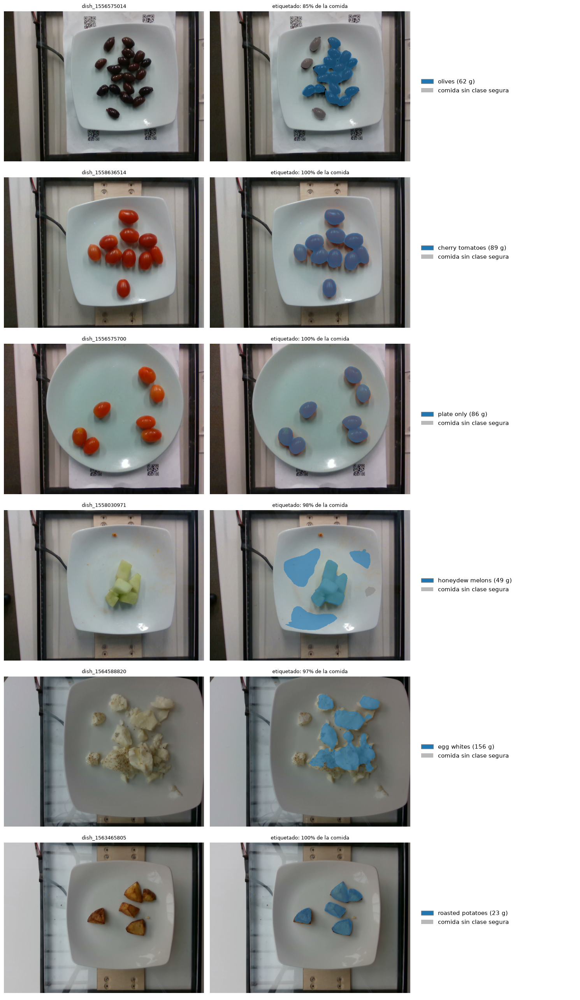

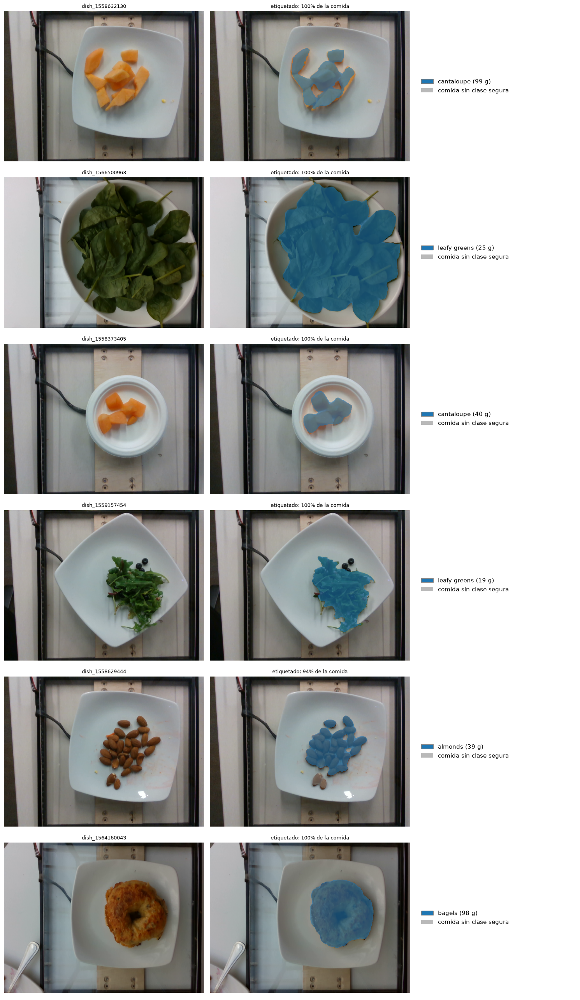

In [21]:
singles = [d for d in done_v2 if len(segmentable(d)) == 1]
rows = []
for d in singles:
    raw = load_raw(d, OUT_V2)
    sizes = np.bincount(raw["region_map"].ravel().astype(np.int64))[1:]
    rows.append(dict(dish=d, clase=list(segmentable(d))[0], fg_frac=float(raw["fg"].mean()),
                     n_comp=len(sizes), frac_main=sizes.max() / sizes.sum() if len(sizes) else 0.0))
sg = pd.DataFrame(rows)
print(len(sg), "platos de una clase | con 2+ componentes de primer plano:", int((sg.n_comp >= 2).sum()))
sus = sg.sort_values(["n_comp", "frac_main"], ascending=[False, True])
display(sus.head(10))

show_samples(OUT_V2, DEC_FINAL, dish_list=list(sus.dish[:6]), n=6, mode="random", min_classes=1)   # sospechosos
show_samples(OUT_V2, DEC_FINAL, dish_list=singles, n=6, mode="random", seed=1, min_classes=1)      # al azar

In [22]:
BIG_G, BIG_PX = 50, 5000     # ingrediente "grande" (g) y región "grande" (px)

def dish_signals(npz_dir, dish_list, dec):
    rows = []
    for d in dish_list:
        raw = load_raw(d, npz_dir); regs = decide(raw, d, dec)
        food = int(raw["fg"].sum()); acc = [r for r in regs if r["accepted"]]
        lab = sum(r["area"] for r in acc)
        pres = sum(r["area"] for r in acc if r["reason"] == "presence")
        got = {r["label"] for r in acc}
        missing = sum(g for l, g in segmentable(d).items() if g >= BIG_G and l not in got)
        big = [r["prob"] for r in acc if r["area"] >= BIG_PX]
        rows.append(dict(dish=d, labeled_frac=lab / food if food else 0.0,
                         presence_frac=pres / lab if lab else 0.0, missing_big_g=missing,
                         min_prob_big=min(big) if big else np.nan, n_classes=len(segmentable(d))))
    return pd.DataFrame(rows).set_index("dish")

def dish_precision(npz_dir, dec, gts):
    out = {}
    for d, gt in gts.items():
        raw = load_raw(d, npz_dir); sem = build_sem(raw, decide(raw, d, dec))
        m = (sem > 0) & (sem < IGNORE) & (gt != IGNORE)
        out[d] = float((sem[m] == gt[m]).mean()) if m.any() else np.nan
    return pd.Series(out, name="precision_real")

def badness(sig):
    r = pd.DataFrame(index=sig.index)
    r["presence_frac"] = sig.presence_frac.rank(pct=True)
    r["missing_big_g"] = sig.missing_big_g.rank(pct=True)
    r["min_prob_big"]  = (-sig.min_prob_big.fillna(1)).rank(pct=True)   # prob baja = peor
    r["labeled_frac"]  = (-sig.labeled_frac).rank(pct=True)
    return r.mean(axis=1)

# 1) ¿Alguna señal predice el error real? (con 40 platos es ruidoso, solo orienta)
sig_clean = dish_signals(OUT_V2, list(gts), DEC_B).join(dish_precision(OUT_V2, DEC_B, gts))
print(sig_clean.corr(method="spearman")["precision_real"].drop("precision_real").round(2))
display(sig_clean.assign(bad=badness(sig_clean)).sort_values("bad", ascending=False)
        [["precision_real", "bad", "presence_frac", "missing_big_g", "min_prob_big"]].round(2).head(10))

# 2) Regla de descarte para la variante B: solo platos de 2+ clases, el 15 % peor
DROP_Q = 0.15
sig_all = dish_signals(OUT_V2, done_v2, DEC_B)
multi = sig_all[sig_all.n_classes >= 2]
bad = badness(multi)
DROP_B = set(bad.sort_values(ascending=False).index[:int(len(multi) * DROP_Q)])
print(len(DROP_B), "platos a descartar de", len(multi))

# 3) ¿El descarte se ensaña con clases concretas?
tot = Counter(l for d in multi.index for l in segmentable(d))
lost = Counter(l for d in DROP_B for l in segmentable(d))
rep = pd.DataFrame({"antes": pd.Series(tot), "quitados": pd.Series(lost)}).fillna(0)
rep["pct"] = (rep.quitados / rep.antes).round(2)
display(rep[(rep.pct > 0.25) & (rep.antes >= 5)].sort_values("pct", ascending=False).head(15))

labeled_frac     0.49
presence_frac   -0.42
missing_big_g   -0.28
min_prob_big    -0.06
n_classes       -0.40
Name: precision_real, dtype: float64


,precision_real,bad,presence_frac,missing_big_g,min_prob_big
dish,,,,,
dish_1563207406,0.94,0.87,0.18,67.00,0.64
dish_1566414412,0.97,0.84,0.75,85.44,0.59
dish_1565194906,0.98,0.79,0.09,51.00,0.55
dish_1563205982,0.81,0.77,0.61,0.00,0.69
dish_1560455263,0.86,0.77,0.12,151.00,1.00
dish_1567785739,1.00,0.75,0.76,0.00,0.64
dish_1566591080,1.00,0.70,0.00,97.00,0.79
dish_1565210073,1.00,0.70,0.00,148.77,0.94
dish_1565021185,1.00,0.66,0.00,124.00,0.77


159 platos a descartar de 1064


,antes,quitados,pct
mangos,10,5.0,0.50
cottage cheese,8,4.0,0.50
brownies,9,4.0,0.44
pasta,17,7.0,0.41
walnuts,5,2.0,0.40
black beans,10,4.0,0.40
caesar dressing,8,3.0,0.38
chia seeds,22,8.0,0.36
parmesan cheese,25,9.0,0.36
pork,83,28.0,0.34


In [23]:
KEEP_MIN, WEAK_MIN = 30, 10
cls = class_stats_for(DEC_A, done_v2)

ing = pd.read_csv(ROOT / "metadata" / "ingredients_metadata.csv")
ing.columns = [c.strip().lower() for c in ing.columns]
print("columnas:", ing.columns.tolist())
name_c = next(c for c in ing.columns if c.startswith("ingr"))
mcols = [next(c for c in ing.columns if c.startswith(p)) for p in ("cal", "fat", "carb", "prot")]
ing = ing.set_index(ing[name_c].str.strip().str.lower())[mcols].astype(float)
ing = ing[~ing.index.duplicated()]

def macro_vec(label):
    members = [n for n, l in MERGE.items() if l == label] + [label]
    rows = [ing.loc[m] for m in members if m in ing.index]
    return pd.concat(rows, axis=1).mean(axis=1) if rows else None

vecs = {c: macro_vec(c) for c in CLASS_NAMES}
M = pd.DataFrame({c: v for c, v in vecs.items() if v is not None}).T
Z = (M - M.mean()) / M.std()
strong = [c for c in cls.index[cls.platos >= KEEP_MIN] if c in Z.index]

def suggest(name, k=3):
    if name not in Z.index:
        return []
    dist = ((Z.loc[strong] - Z.loc[name]) ** 2).sum(axis=1) ** 0.5
    return [(n, round(float(v), 2)) for n, v in dist.nsmallest(k).items()]

weak = cls[(cls.platos > 0) & (cls.platos < KEEP_MIN)]
for name, r in weak.iterrows():
    print(f"{name:28s} platos={int(r.platos):3d}  techo={int(r.techo_total):4d}  ->  {suggest(name)}")

# Llénalo tú mirando las sugerencias. Funde solo lo que además se parezca visualmente.
MERGE_EXPORT = {
    # "sweet potato": "yam",
}
DROP_CLASSES = set(cls.index[cls.platos < WEAK_MIN]) - set(MERGE_EXPORT)   # <10 platos -> 255

def build_lut(merge, drop):
    kept = [n for n in CLASS_NAMES if n not in drop and n not in merge]
    new_id = {n: i + 1 for i, n in enumerate(kept)}
    lut = np.full(256, IGNORE, np.uint8); lut[0] = 0
    for n in CLASS_NAMES:
        if n in drop:
            continue
        tgt, seen = n, set()
        while tgt in merge and tgt not in seen:
            seen.add(tgt); tgt = merge[tgt]
        lut[CLASS_ID[n]] = new_id.get(tgt, IGNORE)
    return lut, ["background"] + kept

lut, class_names_final = build_lut(MERGE_EXPORT, DROP_CLASSES)
print(len(class_names_final) - 1, "clases finales de", len(CLASS_NAMES))

columnas: ['ingr', 'id', 'cal/g', 'fat(g)', 'carb(g)', 'protein(g)']
avocado                      platos= 25  techo=  57  ->  [('roasted potatoes', 0.72), ('scrambled eggs', 1.05), ('corn on the cob', 1.12)]
olives                       platos= 24  techo= 169  ->  [('roasted potatoes', 0.7), ('caesar salad', 0.78), ('carrot', 0.85)]
apple                        platos= 23  techo= 103  ->  [('berries', 0.06), ('pineapple', 0.06), ('carrot', 0.23)]
quinoa                       platos= 23  techo= 108  ->  [('corn on the cob', 0.19), ('rice', 0.36), ('roasted potatoes', 0.47)]
potatoes                     platos= 22  techo=  54  ->  [('sweet potato', 0.13), ('grapes', 0.17), ('berries', 0.25)]
chicken breast               platos= 21  techo=  52  ->  [('chicken', 0.46), ('salmon', 0.89), ('pork', 1.01)]
hash browns                  platos= 21  techo=  51  ->  [('pizza', 1.33), ('cheese pizza', 1.33), ('roasted potatoes', 1.7)]
asparagus                    platos= 20  techo=  36  ->  [('leaf

# 9. Visualización

`show_samples` dibuja, por plato: la **foto**, la **máscara superpuesta** (cada ingrediente de un color; la comida sin clase segura queda en gris apagado) y una **leyenda** con los gramos de la metadata. Los ingredientes de la metadata que el pipeline **no encontró** se marcan como *no detectado*, útil para ver dónde falla.

`mode`: `"random"` (platos al azar), `"mejores"` (los más etiquetados, buenos para la presentación) o `"peores"` (los menos etiquetados, para depurar).
`min_classes`: solo muestra platos con al menos ese número de ingredientes (los de 1 clase son poco vistosos).
Con `save_path` guarda la figura en alta resolución.

In [20]:
def dish_colors(labels):
    cmap = plt.get_cmap("tab10" if len(labels) <= 10 else "tab20")
    return {CLASS_ID[l]: np.array(cmap(i % cmap.N)[:3]) * 255 for i, l in enumerate(labels)}

def overlay(img, sem, colors, alpha=0.6):
    out = img.astype(np.float32).copy()
    for cid, col in colors.items():
        m = sem == cid
        if m.any():
            out[m] = (1 - alpha) * out[m] + alpha * col
    ign = sem == IGNORE
    out[ign] = 0.45 * out[ign] + 0.55 * 128            # comida sin clase segura: gris apagado
    return out.clip(0, 255).astype(np.uint8)

def show_samples(npz_dir, dec, dish_list=None, n=4, mode="random", seed=0, min_classes=2, save_path=None):
    pool = list(dish_list) if dish_list is not None else dishes_in(npz_dir)
    pool = [d for d in pool if len(segmentable(d)) >= min_classes]
    if not pool:
        print("no hay platos con esos criterios"); return
    if mode == "random":
        pick = random.Random(seed).sample(pool, min(n, len(pool)))
    else:
        t = coverage_table(npz_dir, pool, dec).sort_values("labeled_frac", ascending=(mode == "peores"))
        pick = list(t.dish[:n])
    fig, axes = plt.subplots(len(pick), 3, figsize=(15, 4.3 * len(pick)),
                             gridspec_kw=dict(width_ratios=[1, 1, 0.8]), squeeze=False)
    for row, d in zip(axes, pick):
        raw = load_raw(d, npz_dir)
        regs = decide(raw, d, dec)
        sem = build_sem(raw, regs)
        img = load_rgb(d)
        cols = dish_colors(raw["labels"])
        food = int(raw["fg"].sum())
        frac = ((sem > 0) & (sem < IGNORE)).sum() / food if food else 0.0
        row[0].imshow(img);                        row[0].set_title(d, fontsize=9)
        row[1].imshow(overlay(img, sem, cols));    row[1].set_title(f"etiquetado: {frac:.0%} de la comida", fontsize=9)
        row[0].axis("off"); row[1].axis("off"); row[2].axis("off")
        present = set(np.unique(sem).tolist())
        handles = []
        for l, g in sorted(segmentable(d).items(), key=lambda kv: -kv[1]):
            ok = CLASS_ID[l] in present
            handles.append(Patch(facecolor=tuple(cols[CLASS_ID[l]] / 255) if ok else "white", edgecolor="gray",
                                 label=f"{l} ({g:.0f} g)" + ("" if ok else "  - no detectado")))
        handles.append(Patch(facecolor="gray", alpha=0.55, label="comida sin clase segura"))
        row[2].legend(handles=handles, loc="center left", fontsize=11, frameon=False)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print("guardado en", save_path)
    plt.show()

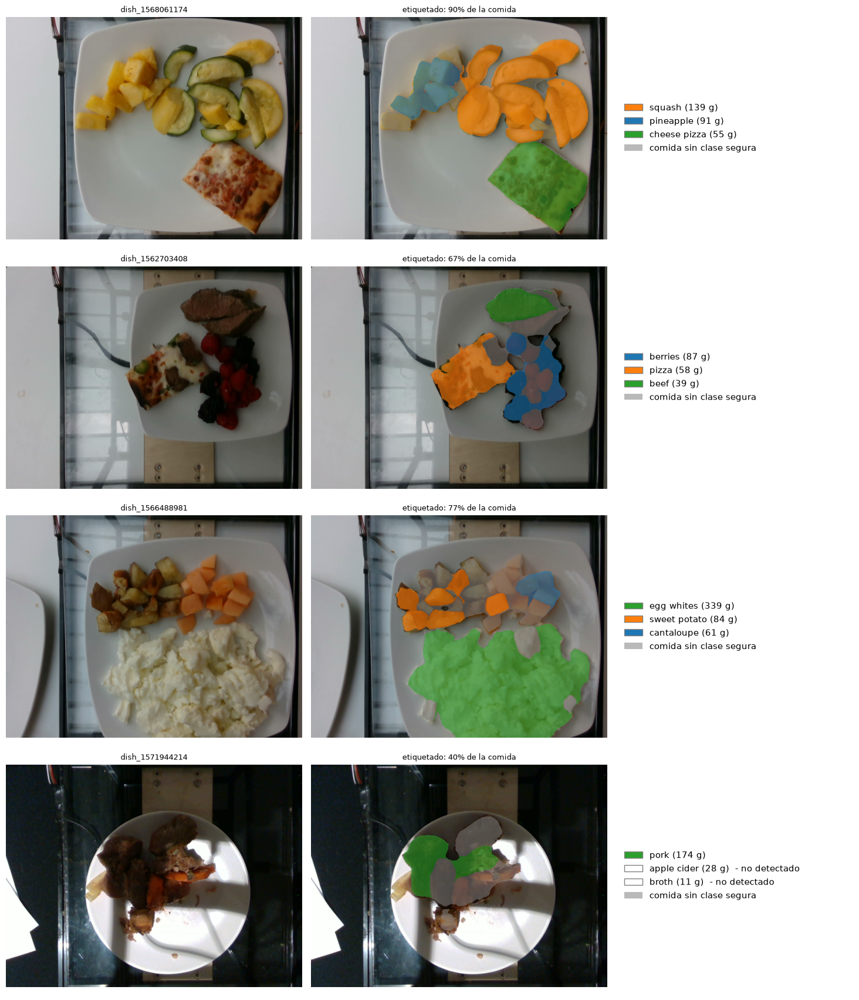

guardado en ejemplos_etiquetado.png


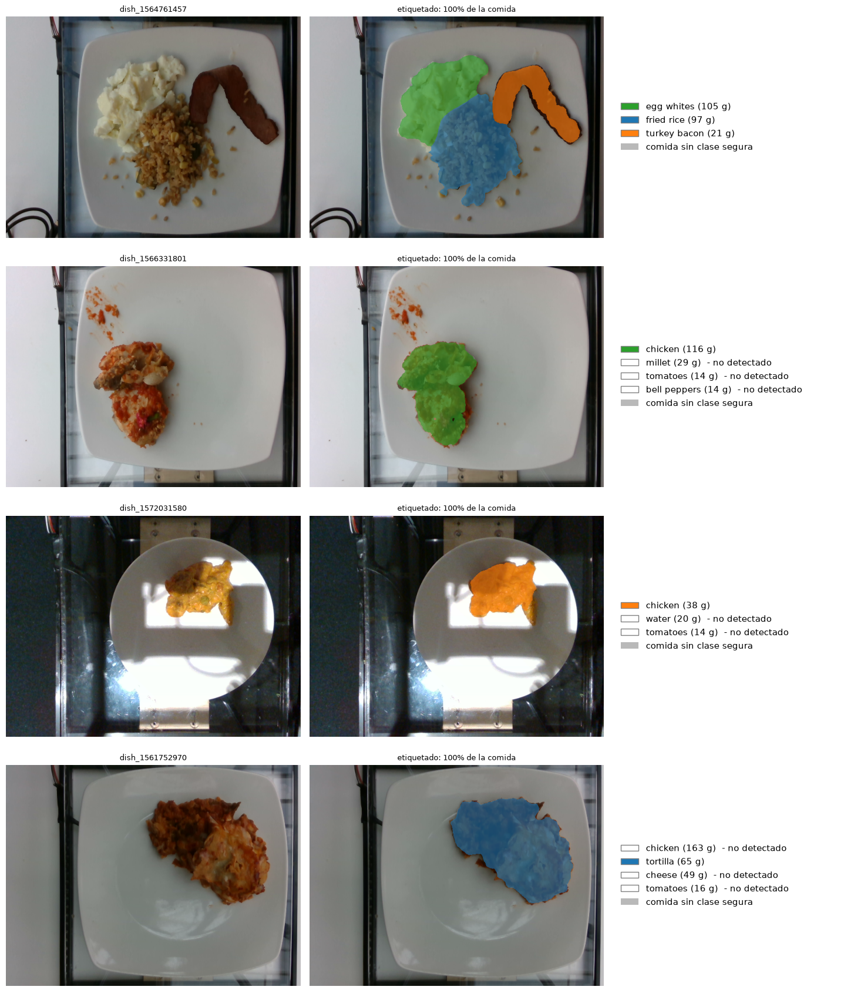

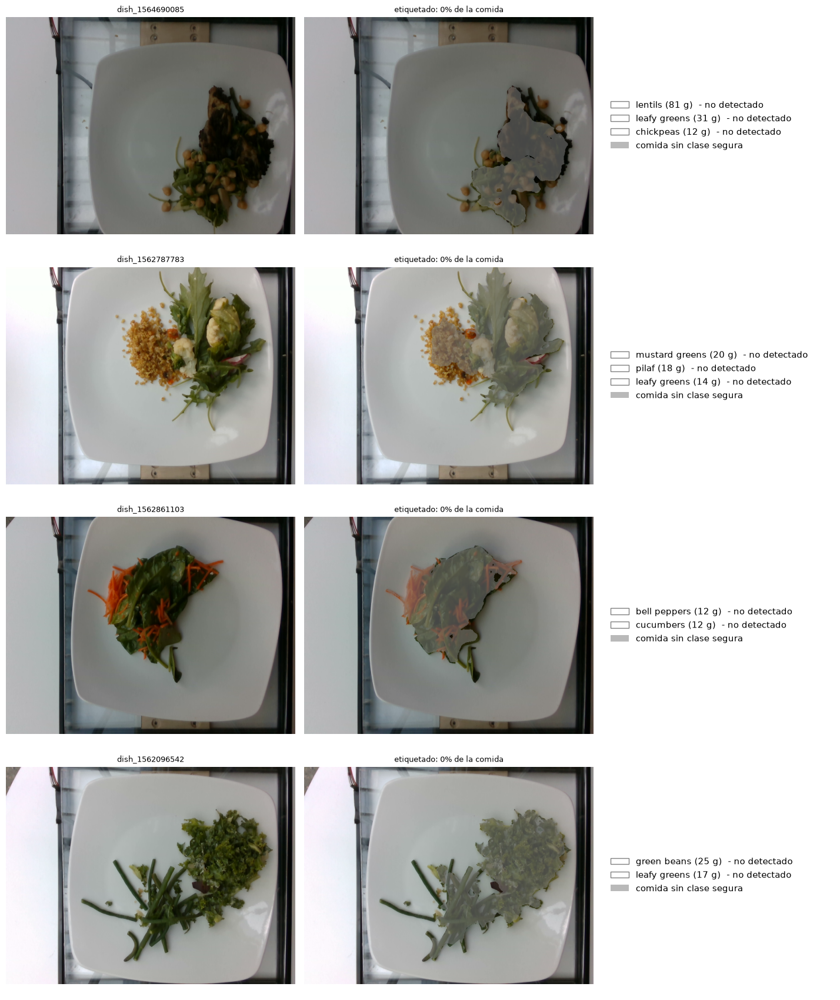

In [ ]:
# Platos al azar (cambia seed para ver otros)
show_samples(OUT_V2, DEC_FINAL, n=4, mode="random", seed=0, min_classes=3)

# Para la presentación: los mejores etiquetados, guardados en alta resolución
show_samples(OUT_V2, DEC_FINAL, n=4, mode="mejores", min_classes=3, save_path="ejemplos_etiquetado.png")

# Para depurar: los peores
show_samples(OUT_V2, DEC_FINAL, n=4, mode="peores", min_classes=2)

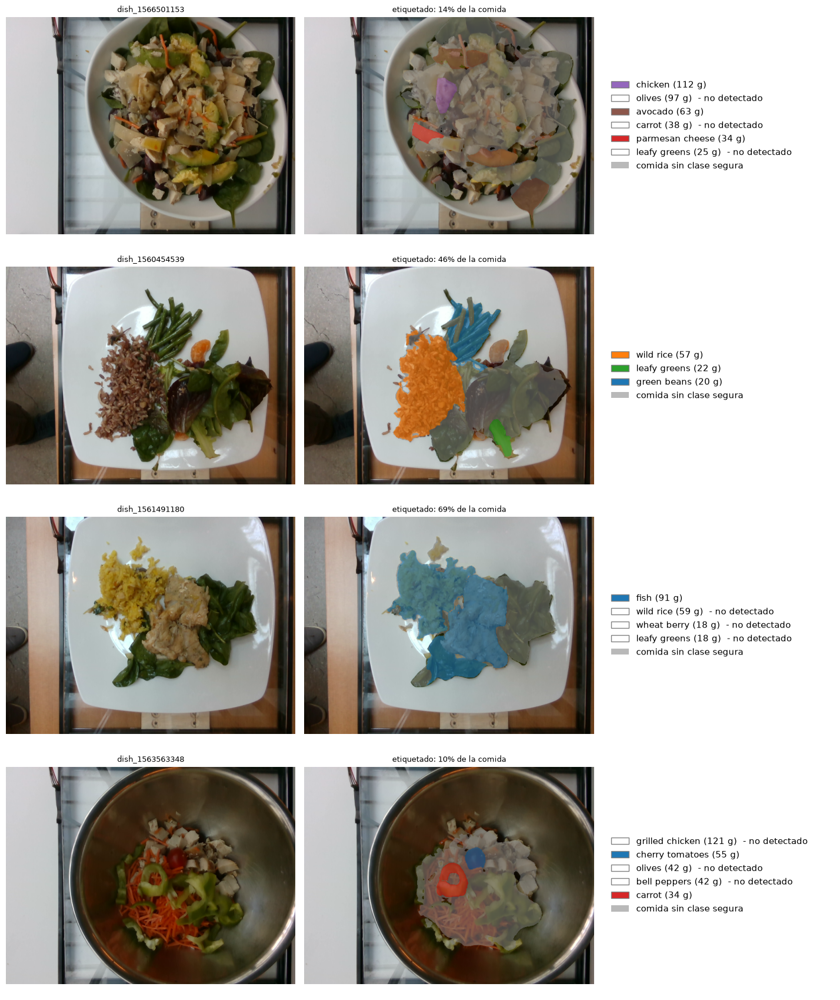

In [ ]:
last20 = [p.stem for p in sorted(OUT_V2.glob("*.npz"), key=lambda p: p.stat().st_mtime)[-20:]]
show_samples(OUT_V2, DEC_FINAL, dish_list=last20, n=4, min_classes=1, seed=1)

In [ ]:
# ¿cuántos platos tienen ingredientes con nombre vacío?
print(sum(any(not i["name"].strip() for i in dishes[d]["ingredients"]) for d in usable))
print([n for n in CLASS_NAMES if len(n.strip()) < 3])      # nombres raros en el vocabulario

49
['']


# 10. Exportar el dataset para el fine-tuning

Escribe:
- `labels/<plato>.png` (`uint8`: **0 = fondo, 1..K = clase, 255 = ignorar**). Usa `ignore_index=255` en la pérdida.
- `classes.json`: mapeo id → nombre. **Guárdalo junto al dataset** (los ids dependen de `EXCLUDE`/`MERGE`).
- `manifest.csv`: ruta de imagen y etiqueta, fracción etiquetada y **split train/val por plato**.
- `class_stats.csv`: platos y píxeles por clase, para ver qué clases quedan débiles.

`min_labeled_frac` descarta platos con muy poca comida etiquetada (0.3 es un punto de partida). Las clases con pocos platos (< `rare_threshold`) se listan al final: son las que el modelo aprenderá peor.

In [24]:
def export_dataset_v3(npz_dir, dec, out_dir, lut, class_names, val_dishes, exclude=(), drop_dishes=(),
                      min_labeled_frac=0.1, rare_threshold=30):
    out_dir = Path(out_dir); (out_dir / "labels").mkdir(parents=True, exist_ok=True)
    (out_dir / "classes.json").write_text(json.dumps(
        {"classes": class_names, "ignore_index": IGNORE}, indent=1), encoding="utf-8")
    K = len(class_names) - 1
    px, nd, rows = np.zeros(K + 1, np.int64), np.zeros(K + 1, np.int64), []
    for d in dishes_in(npz_dir):
        raw = load_raw(d, npz_dir)
        sem = lut[build_sem(raw, decide(raw, d, dec))]
        food = int(raw["fg"].sum())
        lab = (sem > 0) & (sem < IGNORE)
        frac = float(lab.sum() / food) if food else 0.0
        reason = "test" if d in exclude else "dropped_quality" if d in drop_dishes \
                 else "low_coverage" if frac < min_labeled_frac else ""
        if reason == "":
            Image.fromarray(sem).save(out_dir / "labels" / f"{d}.png")
            c = np.bincount(sem[lab].astype(np.int64), minlength=K + 1)
            px += c; nd += (c > 0)
        rows.append(dict(dish=d, image=str(ROOT / "realsense_overhead" / d / "rgb.png"),
                         label=str(Path("labels") / f"{d}.png") if reason == "" else "",
                         labeled_frac=round(frac, 3), n_classes=len(raw["labels"]), reason=reason))
    man = pd.DataFrame(rows)
    ok = man.reason == ""
    man["split"] = ""
    man.loc[ok, "split"] = np.where(man.loc[ok, "dish"].isin(val_dishes), "val", "train")
    man.loc[man.reason == "test", "split"] = "test"
    man.to_csv(out_dir / "manifest.csv", index=False)
    stats = pd.DataFrame(dict(clase=class_names[1:], platos=nd[1:], pixeles=px[1:])) \
              .sort_values("platos", ascending=False)
    stats.to_csv(out_dir / "class_stats.csv", index=False)
    print(out_dir, "->", man.split.value_counts().to_dict(), "| descartados:", man.reason.value_counts().to_dict())
    print(int((stats.platos < rare_threshold).sum()), "de", K, f"clases con <{rare_threshold} platos")
    return man, stats

EXCLUDE_DISHES = {p.stem for p in (CLEAN_DIR / "regions").glob("*.npz")} | \
                 {p.stem for p in Path("clean_set_val/regions").glob("*.npz")}
cand_val = [d for d in done_v2 if d not in EXCLUDE_DISHES]
VAL_DISHES = set(random.Random(0).sample(cand_val, int(len(cand_val) * 0.1)))

EXPORT = True
if EXPORT:
    manA, statsA = export_dataset_v3(OUT_V2, DEC_A, "dataset_A_minimo", lut, class_names_final,
                                     VAL_DISHES, exclude=EXCLUDE_DISHES, min_labeled_frac=0.1)
    manB, statsB = export_dataset_v3(OUT_V2, DEC_B, "dataset_B_estricto", lut, class_names_final,
                                     VAL_DISHES, exclude=EXCLUDE_DISHES, drop_dishes=DROP_B, min_labeled_frac=0.1)
    display(statsB[statsB.platos < 30].head(20))

dataset_A_minimo -> {'train': 1120, '': 125, 'val': 122, 'test': 40} | descartados: {'': 1242, 'low_coverage': 125, 'test': 40}
32 de 67 clases con <30 platos
dataset_B_estricto -> {'train': 991, '': 271, 'val': 105, 'test': 40} | descartados: {'': 1096, 'dropped_quality': 153, 'low_coverage': 118, 'test': 40}
35 de 67 clases con <30 platos


,clase,platos,pixeles
25,cucumbers,28,378887
55,steak,27,396361
65,yam,25,172326
46,potatoes,20,275673
2,apple,19,229848
34,hash browns,19,425014
4,avocado,19,329556
42,pears,18,253976
21,chicken breast,16,147525
31,fried rice,15,326631


In [25]:
def export_clean_refs(out_dir="clean_refs"):
    out = Path(out_dir); (out / "labels").mkdir(parents=True, exist_ok=True)
    (out / "classes.json").write_text(json.dumps(
        {"classes": class_names_final, "ignore_index": IGNORE}, indent=1), encoding="utf-8")
    rows = []
    for group, cdir in [("clean", "clean_set"), ("val", "clean_set_val")]:
        if not (Path(cdir) / "regions_gt.csv").exists():
            continue
        for d, sem in load_clean_gt(cdir).items():
            Image.fromarray(lut[sem]).save(out / "labels" / f"{d}.png")
            rows.append(dict(dish=d, label=str(Path("labels") / f"{d}.png"), group=group))
    pd.DataFrame(rows).to_csv(out / "manifest.csv", index=False)
    print(len(rows), "platos de referencia ->", out)

export_clean_refs()

40 platos de referencia -> clean_refs
